# Human decidual boundary — inspecting the fib↔dec call

**The question.** Human stroma carries two labels, `endometrial_fibroblast` and `decidual_cell`, assigned by a
majority vote of a transferred reference over 34 within-lineage leiden_3.0 clusters. Nine clusters (8,072 cells) had
vote purity < 0.80. Scoring the `lineage_spec.yaml` panel found **two distinct ambiguous populations**:

| class | clusters | cells | signature |
|---|---|---|---|
| **A** LEFTY2-intermediate | 3, 9, 10, 12, 19, 22, 25, 29 | 6,058 | LEFTY2 detection 0.20–0.35, between the bodies; votes split 4/4 — weak decidual signal |
| **B** double-positive | 2, 5, 8, 11, 24 | 6,619 | LEFTY2 near-decidual **and** fibroblast/ECM markers at the top of the range (mean DCN percentile 0.92 vs 0.26 for high-purity decidual) — co-expression, not weak signal |

**B is 82% of the low-purity cells; A is 18%.** A single threshold on decidual markers separates A and misses B
entirely, which is why the call defaults to the union of both. B is the class that looks like a transitional state
on marker evidence — retained ECM program alongside an acquired decidual marker.

This notebook asks whether either is a **real boundary population** (the human analogue of mouse
`decidual_boundary`) or an artifact of putting a threshold through a continuum.

**Three tests, in order of how much they'd settle it:**

| § | test | what a real boundary population looks like |
|---|---|---|
| 6 | **spatial** | boundary cells sit at the fib/dec interface — their spatial neighbours are a mix of both, more so than for either pure type |
| 4 | **replication** | present in every sample, not one |
| 4, 7 | **axes** | intermediate on isodepth (measured) and pseudotime; matches where mouse `decidual_boundary` sits |

**Read-only.** No object is modified; per-cell calls go to CSV. CPU, ~10 min.
`--partition eddy --mem 200G --cpus-per-task 8` in `rsc_uv`.

## 1. Setup and load

In [1]:
import pathlib, json, h5py, warnings
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.stats import spearmanr, mannwhitneyu
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

X    = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
SRC  = X/"data/deliverables/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad"
STRO = X/"data/interim/reannotated/human_stromal.h5ad"      # the within-lineage clustering the vote was taken on
ISO  = X/"results/isodepth/human_fibdec_isodepth.h5ad"      # isodepth_consensus
VOTE = X/"resources/annotations/human_stromal.csv"          # the committed cluster -> label table
SUBCL= X/"results/human_dec_subclusters.csv"                # optional: 4 decidual subclusters at leiden_0.3
MOUSE= X/"data/deliverables/2026_09_02_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"   # § 7 reference
OUT  = X/"results/human_boundary"; OUT.mkdir(parents=True, exist_ok=True)
sc.settings.figdir = str(OUT)

RES     = "leiden_scVI_3.0"
SUBORDER  = ["endometrial_fibroblast", "decidual_cell"]
CALLORDER = ["endometrial_fibroblast", "boundary_candidate", "decidual_cell"]
CALLPAL   = dict(zip(CALLORDER, ["#3b6ea5", "#e8a33d", "#9c3d5a"]))

CHECKS = []
def verify(label, got, note=""):
    ok = bool(got); CHECKS.append((label, ok, str(got), note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else "")); return ok

for p in (SRC, STRO, ISO, VOTE):
    verify(f"exists {p.name}", p.exists(), str(p))

PASS  exists 2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad   [True]  /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/deliverables/2026_08_28_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
PASS  exists human_stromal.h5ad   [True]  /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/data/interim/reannotated/human_stromal.h5ad
PASS  exists human_fibdec_isodepth.h5ad   [True]  /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/isodepth/human_fibdec_isodepth.h5ad
PASS  exists human_stromal.csv   [True]  /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/resources/annotations/human_stromal.csv


In [2]:
a = sc.read_h5ad(SRC)
print(a.shape, "| layers:", list(a.layers), "| obsm:", list(a.obsm))
o = a.obs.copy()
print("\ncell_type:", o.cell_type.astype(str).value_counts().to_dict())
print("cell_subtype:", o.cell_subtype.astype(str).value_counts().to_dict())
print("sample:", o["sample"].astype(str).value_counts().to_dict())
print("tissue_section:", o.tissue_section.astype(str).value_counts().to_dict())

# phase is not its own column on this object -- derive it from the sample name and prove the mapping is clean
samp = o["sample"].astype(str)
phase = pd.Series(np.where(samp.str.startswith("secretory"), "secretory",
                  np.where(samp.str.startswith("menstrual"), "menstrual", "UNMAPPED")), index=o.index)
verify("every sample maps to one phase", (phase != "UNMAPPED").all(),
       f"unmapped samples: {sorted(set(samp[phase=='UNMAPPED']))}")
o["phase"] = pd.Categorical(phase, categories=["secretory", "menstrual"])
print("\nphase:", o.phase.value_counts().to_dict())
verify("counts layer is integer", np.allclose((c := a.layers["counts"][:200].toarray()), np.round(c)))

(47533, 36601) | layers: ['counts'] | obsm: ['X_scVI', 'X_scVI_wholetissue', 'X_spatial', 'X_umap_scVI', 'X_umap_wholetissue']

cell_type: {'endometrial_fibroblast': 25885, 'decidual_cell': 21648}
cell_subtype: {'endometrial_fibroblast': 25885, 'decidual_cell': 21648}
sample: {'secretory_mck6a': 9122, 'secretory_mck6b': 8926, 'menstrual_mck5b': 8361, 'menstrual_mck5a': 8237, 'menstrual_mck5c': 7494, 'secretory_mck6c': 5393}
tissue_section: {np.str_('nan'): 14286, 'secretory_mck6a__A': 7293, 'secretory_mck6b__A': 7131, 'menstrual_mck5b__A': 5148, 'menstrual_mck5a__A': 4863, 'menstrual_mck5c__A': 4487, 'secretory_mck6c__A': 4325}
PASS  every sample maps to one phase   [True]  unmapped samples: []

phase: {'menstrual': 24092, 'secretory': 23441}
PASS  counts layer is integer   [True]


True

In [3]:
# --- join the within-lineage cluster id, the per-cell reference call, and isodepth (obs-only reads) ---
with h5py.File(STRO, "r") as f:
    scols = list(f["obs"].keys())
    S = pd.DataFrame({RES: np.asarray(read_elem(f["obs/"+RES])).astype(str),
                      "celltype_ref": np.asarray(read_elem(f["obs/celltype_ref"])).astype(str)},
                     index=read_elem(f["obs/_index"]))
    for k in [c for c in scols if c.startswith("score_")]:
        S[k] = pd.to_numeric(read_elem(f["obs/"+k]), errors="coerce")
print("stromal object:", S.shape, "| clusters:", S[RES].nunique(), "| score cols:", [c for c in S if c.startswith("score_")])

with h5py.File(ISO, "r") as f:
    I = pd.DataFrame({"isodepth_consensus": pd.to_numeric(read_elem(f["obs/isodepth_consensus"]), errors="coerce")},
                     index=read_elem(f["obs/_index"]))

o = o.join(S, how="left").join(I, how="left")
verify("cluster id joined", (r := o[RES].notna().mean()) > 0.99, f"join rate {r:.4f}")
verify("isodepth joined",   (r := o.isodepth_consensus.notna().mean()) > 0.90, f"join rate {r:.4f}")
verify("reference call joined", o.celltype_ref.notna().mean() > 0.99)
print("\ncells not in the stromal object (should be 0 -- fib/dec is a subset):", int(o[RES].isna().sum()))
print("cells with a QC'd coordinate:", int(o.x_um_qc.notna().sum()), "/", len(o))

V = pd.read_csv(VOTE, dtype=str).set_index("cluster")
V["purity"] = V["note"].str.extract(r"purity (\d\.\d+)").astype(float) if "note" in V else np.nan
print("\nvote table:", V.shape, "| labels:", sorted(set(V.label)), "| clusters with purity < 0.8:",
      sorted(V.index[V.purity < 0.8].tolist(), key=lambda s: int(s)))

stromal object: (48004, 8) | clusters: 34 | score cols: ['score_decidual cells', 'score_endometrial fibroblasts', 'score_epithelial cells', 'score_immune cells', 'score_perivascular cells', 'score_smooth muscle cells']


PASS  cluster id joined   [True]  join rate 1.0000
PASS  isodepth joined   [True]  join rate 1.0000
PASS  reference call joined   [True]

cells not in the stromal object (should be 0 -- fib/dec is a subset): 0
cells with a QC'd coordinate: 33247 / 47533

vote table: (34, 5) | labels: ['decidual_cell', 'endometrial_fibroblast', 'perivascular_cell'] | clusters with purity < 0.8: ['2', '5', '8', '10', '11', '19', '24', '25', '29']


## 2. Which markers actually discriminate

The `lineage_spec.yaml` human panel is `PDGFRA/DCN/LUM/COL1A1` (fibroblast) and `PRL/IGFBP1/LEFTY2/FOXO1` (decidual).
Two additions here: the **mouse** panel's decidual genes are different (`Prl8a2/Ptgs2/Bmp2/Wnt4/Hand2`), and their human
orthologs `PTGS2/BMP2/WNT4/HAND2` are *not* in the human panel — they may discriminate where `PRL` does not.
Each gene is ranked by AUROC for the committed dec-vs-fib label, so "which markers work" is measured, not assumed.

In [4]:
PANEL = {"fibroblast": ["PDGFRA","DCN","LUM","COL1A1"],
         "decidual":   ["PRL","IGFBP1","LEFTY2","FOXO1"],
         "decidual_mousepanel": ["PTGS2","BMP2","WNT4","HAND2"],
         "prolif":     ["MKI67","TOP2A"],
         "contam":     ["CDH1","PECAM1","PTPRC","ACTA2"]}
absent = {k: [g for g in v if g not in a.var_names] for k, v in PANEL.items()}
PANEL  = {k: [g for g in v if g in a.var_names] for k, v in PANEL.items()}
verify("panel genes present", not any(absent.values()), f"absent: { {k:v for k,v in absent.items() if v} }")

# log-CP10k from counts, the convention the dotplots use
a.X = a.layers["counts"].copy(); sc.pp.normalize_total(a, target_sum=1e4); sc.pp.log1p(a)
genes = [g for v in PANEL.values() for g in v]
E = pd.DataFrame(a[:, genes].X.toarray(), columns=genes, index=a.obs_names)

y = (o.cell_type.astype(str) == "decidual_cell").astype(int).to_numpy()
auroc = pd.DataFrame({"group": {g: k for k, v in PANEL.items() for g in v},
                      "auroc_dec_vs_fib": {g: roc_auc_score(y, E[g]) for g in genes},
                      "det_overall": (E > 0).mean(),
                      "det_in_dec": (E[y == 1] > 0).mean(),
                      "det_in_fib": (E[y == 0] > 0).mean()}).round(3).sort_values("auroc_dec_vs_fib", ascending=False)
print("=== per-gene discrimination of the committed label ===")
print(auroc.to_string())
best = auroc.index[0]
verify("at least one decidual marker with AUROC > 0.7",
       (auroc[auroc.group.str.startswith("decidual")].auroc_dec_vs_fib > 0.7).any(),
       f"best overall: {best} ({auroc.auroc_dec_vs_fib.iloc[0]:.3f})")
auroc.to_csv(OUT/"marker_discrimination.csv")

PASS  panel genes present   [True]  absent: {}


=== per-gene discrimination of the committed label ===
                      group  auroc_dec_vs_fib  det_overall  det_in_dec  det_in_fib
LUM              fibroblast             0.757        0.466       0.723       0.251
FOXO1              decidual             0.716        0.746       0.863       0.647
LEFTY2             decidual             0.672        0.276       0.459       0.123
COL1A1           fibroblast             0.606        0.746       0.808       0.695
PDGFRA           fibroblast             0.553        0.700       0.743       0.664
IGFBP1             decidual             0.539        0.039       0.081       0.004
BMP2    decidual_mousepanel             0.526        0.042       0.071       0.018
WNT4    decidual_mousepanel             0.508        0.063       0.072       0.056
ACTA2                contam             0.507        0.264       0.277       0.254
PRL                decidual             0.507        0.007       0.015       0.001
PECAM1               contam     

decidual markers usable as thresholds (AUROC > 0.6 AND background in fibroblasts < 0.35):
   drop  FOXO1    AUROC=0.716 det_in_fib=0.647  background 0.65 too high
   KEEP  LEFTY2   AUROC=0.672 det_in_fib=0.123  
   drop  IGFBP1   AUROC=0.539 det_in_fib=0.004  AUROC too low
   drop  BMP2     AUROC=0.526 det_in_fib=0.018  AUROC too low
   drop  WNT4     AUROC=0.508 det_in_fib=0.056  AUROC too low
   drop  PRL      AUROC=0.507 det_in_fib=0.001  AUROC too low
   drop  PTGS2    AUROC=0.500 det_in_fib=0.000  AUROC too low
   drop  HAND2    AUROC=0.496 det_in_fib=0.182  AUROC too low
PASS  at least one usable threshold marker   [True]  ['LEFTY2']

band will be cut on: LEFTY2

fibroblast-panel genes, direction on THIS dataset:
   inverted  LUM      AUROC_dec=0.757  det_in_dec=0.723 det_in_fib=0.251
   inverted  COL1A1   AUROC_dec=0.606  det_in_dec=0.808 det_in_fib=0.695
   ECM axis  PDGFRA   AUROC_dec=0.553  det_in_dec=0.743 det_in_fib=0.664
   ECM axis  DCN      AUROC_dec=0.453  det_in_dec=0.

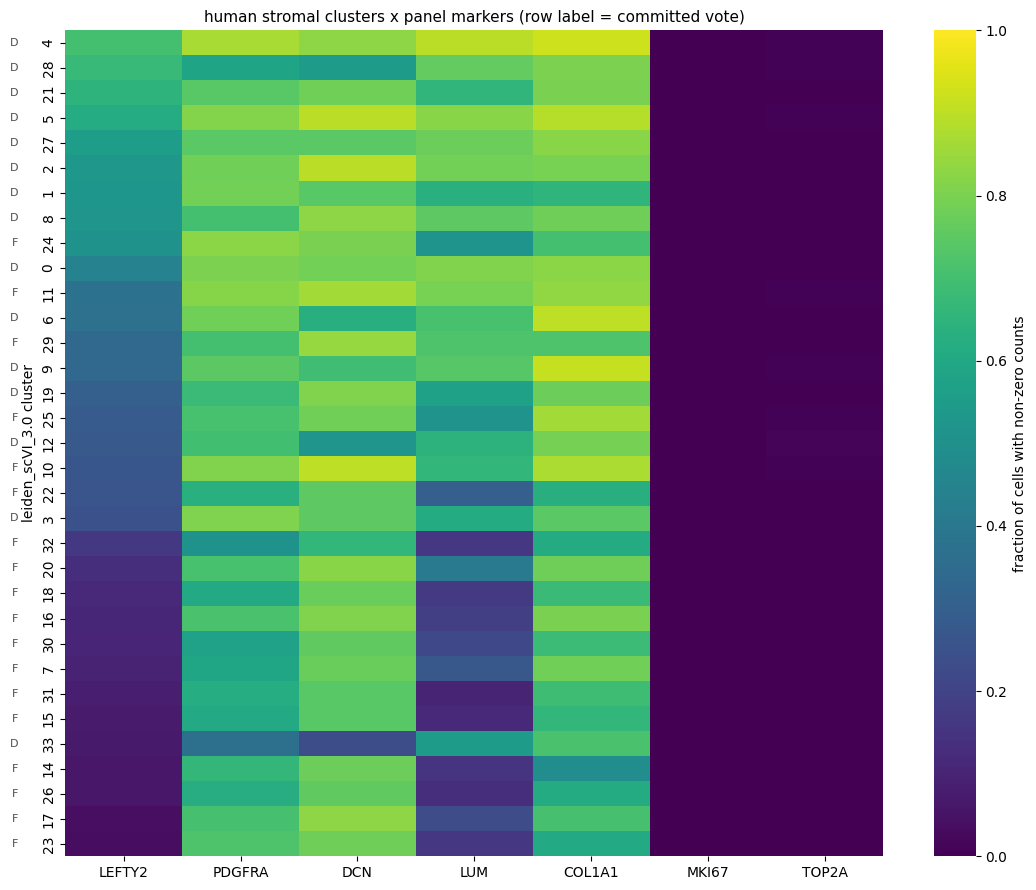

In [5]:
# ====================================================================================================
# §2b — marker selection (the cell starting `# A marker used as a THRESHOLD`)
# ====================================================================================================
# per-cluster detection fraction, ordered by the best decidual marker
# A marker used as a THRESHOLD needs two properties, and AUROC only tests one of them: it must rank
# cells well AND have low background in the negative class. FOXO1 has the best decidual AUROC (0.716)
# but is detected in ~65% of fibroblasts, so averaging it into a detection score shifts every cluster
# above any threshold calibrated on a low-background gene -- which is what emptied the fibroblast body
# in the first version of this notebook. Require both.
MAXBG = 0.35
cand = auroc[auroc.group.str.startswith("decidual")]
DECGENES = [g for g in cand.index if cand.auroc_dec_vs_fib[g] > 0.6 and cand.det_in_fib[g] < MAXBG]
print(f"decidual markers usable as thresholds (AUROC > 0.6 AND background in fibroblasts < {MAXBG}):")
for g in cand.index:
    keep = g in DECGENES
    why = "" if keep else ("AUROC too low" if cand.auroc_dec_vs_fib[g] <= 0.6 else f"background {cand.det_in_fib[g]:.2f} too high")
    print(f"   {'KEEP' if keep else 'drop'}  {g:8s} AUROC={cand.auroc_dec_vs_fib[g]:.3f} det_in_fib={cand.det_in_fib[g]:.3f}  {why}")
verify("at least one usable threshold marker", len(DECGENES) > 0, f"{DECGENES}")
BANDGENE = DECGENES[0]      # the band is cut on ONE gene so its thresholds keep their meaning
print("\nband will be cut on:", BANDGENE)

# two observations from the same table, worth having in front of you:
# The ECM axis (class B, section 4) must use fibroblast-panel genes that are actually fibroblast-enriched
# HERE. On this dataset most of the panel is not: AUROC-for-decidual > 0.5 means the gene is higher in
# DECIDUAL cells. Select rather than assume.
fibcand = auroc[auroc.group == "fibroblast"]
ECMGENES = [g for g in fibcand.index if fibcand.auroc_dec_vs_fib[g] <= 0.60]
inverted = [g for g in fibcand.index if g not in ECMGENES]
print(f"\nfibroblast-panel genes, direction on THIS dataset:")
for g in fibcand.index:
    print(f"   {'ECM axis' if g in ECMGENES else 'inverted'}  {g:8s} AUROC_dec={fibcand.auroc_dec_vs_fib[g]:.3f}  "
          f"det_in_dec={fibcand.det_in_dec[g]:.3f} det_in_fib={fibcand.det_in_fib[g]:.3f}")
if inverted: print(f"   -> {', '.join(inverted)} are detected MORE in decidual cells; excluded from the ECM axis.")
verify("at least one fibroblast-enriched ECM gene", len(ECMGENES) > 0, f"{ECMGENES}")
mp = auroc[auroc.group == "decidual_mousepanel"]
if len(mp): print(f"NOTE  mouse-panel orthologs do not transfer: AUROC {mp.auroc_dec_vs_fib.min():.3f}-{mp.auroc_dec_vs_fib.max():.3f} "
                  f"({', '.join(mp.index)}) -- the mouse decidual markers are not usable in human.")

cl = o[RES].astype(str)
frac = (E > 0).groupby(cl).mean(); mean = E.groupby(cl).mean()
ORD  = frac[BANDGENE].sort_values(ascending=False).index.tolist()

tab = pd.concat([cl.value_counts().rename("n"),
                 V[["label","purity"]].rename(columns={"label":"vote"}),
                 frac[[g for g in DECGENES]].add_prefix("det_").round(3),
                 mean[ECMGENES].mean(axis=1).rename("ecm_mean").round(3),
                 mean[PANEL["prolif"]].mean(axis=1).rename("mean_prolif").round(2),
                 mean[PANEL["contam"]].mean(axis=1).rename("mean_contam").round(2)], axis=1).reindex(ORD)
tab.index.name = "cluster"
print(f"\n=== per-cluster, ordered by {BANDGENE} detection ===")
print(tab.to_string())
tab.to_csv(OUT/"cluster_marker_table.csv")

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(frac.reindex(ORD)[DECGENES + PANEL["fibroblast"] + PANEL["prolif"]], cmap="viridis", vmin=0, vmax=1,
            cbar_kws=dict(label="fraction of cells with non-zero counts"), ax=ax)
for i, c_ in enumerate(ORD):
    ax.text(-0.4, i + 0.5, ("D" if V.label.get(c_) == "decidual_cell" else "F" if V.label.get(c_) == "endometrial_fibroblast" else "?"),
            ha="right", va="center", fontsize=8, color="0.3")
ax.set_title("human stromal clusters x panel markers (row label = committed vote)", fontsize=11)
ax.set_ylabel(f"{RES} cluster"); fig.tight_layout(); fig.savefig(OUT/"cluster_marker_heatmap.png", dpi=130, bbox_inches="tight")


## 3. Per-cell decidual score — continuum or two modes?

Cluster-level detection can look intermediate either because the cluster is a mix of pure cells or because its cells
are individually intermediate. This scores each cell (scanpy `score_genes`, the kept decidual markers against a
random background) and asks how much the two labels overlap. `stro7_margin`, already on the object from the
reference vote, is compared against it as an independent per-cell measure.

dec_score        AUROC=0.670  dec median=-0.496  fib median=-0.792  dec cells inside fib's 10-90% band = 0.562
dec_minus_fib    AUROC=0.579  dec median=-0.833  fib median=-1.106  dec cells inside fib's 10-90% band = 0.592
stro7_margin     AUROC=0.141  dec median=-0.133  fib median=-0.045  dec cells inside fib's 10-90% band = 0.314
FAIL  dec_score separates the labels   [False]  AUROC 0.670

spearman(dec_score, stro7_margin) = -0.172


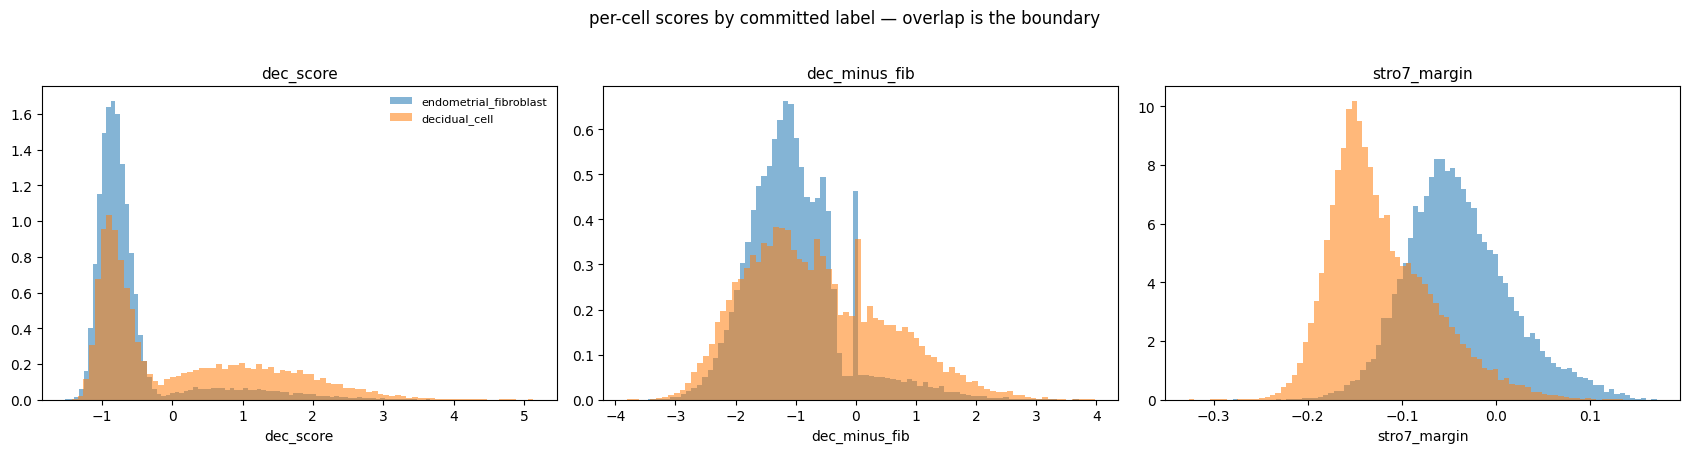

In [6]:
sc.tl.score_genes(a, DECGENES, score_name="dec_score", random_state=0)
sc.tl.score_genes(a, PANEL["fibroblast"], score_name="fib_score", random_state=0)
o["dec_score"], o["fib_score"] = a.obs.dec_score.to_numpy(), a.obs.fib_score.to_numpy()
o["dec_minus_fib"] = o.dec_score - o.fib_score

for col in ("dec_score", "dec_minus_fib", "stro7_margin"):
    if col not in o: continue
    v = pd.to_numeric(o[col], errors="coerce")
    d, f_ = v[y == 1].dropna(), v[y == 0].dropna()
    if len(d) and len(f_):
        auc = roc_auc_score(np.r_[np.ones(len(d)), np.zeros(len(f_))], np.r_[d, f_])
        # overlap: fraction of each label inside the other's central 80%
        lo, hi = f_.quantile(0.10), f_.quantile(0.90)
        print(f"{col:16s} AUROC={auc:.3f}  dec median={d.median():+.3f}  fib median={f_.median():+.3f}  "
              f"dec cells inside fib's 10-90% band = {((d>=lo)&(d<=hi)).mean():.3f}")
verify("dec_score separates the labels", roc_auc_score(y, o.dec_score) > 0.7, f"AUROC {roc_auc_score(y, o.dec_score):.3f}")
if "stro7_margin" in o:
    print("\nspearman(dec_score, stro7_margin) =", round(float(spearmanr(o.dec_score, pd.to_numeric(o.stro7_margin, errors='coerce'), nan_policy='omit').statistic), 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, col in zip(axes, ("dec_score", "dec_minus_fib", "stro7_margin" if "stro7_margin" in o else "fib_score")):
    v = pd.to_numeric(o[col], errors="coerce")
    for lab in SUBORDER:
        ax.hist(v[o.cell_type.astype(str) == lab].dropna(), bins=80, alpha=0.55, label=lab, density=True)
    ax.set_title(col, fontsize=11); ax.set_xlabel(col)
axes[0].legend(fontsize=8, frameon=False)
fig.suptitle("per-cell scores by committed label — overlap is the boundary", y=1.02)
fig.tight_layout(); fig.savefig(OUT/"per_cell_score_distributions.png", dpi=130, bbox_inches="tight")

## 4. The intermediate clusters — replication and axis position

Two things a real population must show and a threshold artifact need not: presence in **every sample** (an artifact
of one section's ambient background would not replicate) and an **intermediate position** on the measured spatial
axis (`isodepth_consensus`) and on pseudotime.

In [7]:
# ====================================================================================================
# §4 — band + class B (the cell starting `# Class A = clusters`)
# ====================================================================================================
# Class A = clusters whose BANDGENE detection falls between the two bodies. Cut on one gene, so the
# thresholds mean what they say (LEFTY2 detection runs 0.03-0.70 across clusters).
det = frac[BANDGENE].reindex(tab.index)
LO, HI = 0.20, 0.35     # <- edit and re-run this cell to move the band
print(f"{BANDGENE} detection across clusters: {det.min():.3f} - {det.max():.3f}   band = [{LO}, {HI}]")
verify("thresholds are on the same scale as the score",
       (det < LO).any() and (det > HI).any(),
       f"{int((det<LO).sum())} clusters below LO, {int((det>HI).sum())} above HI")
band = det[(det >= LO) & (det <= HI)].index.tolist()
body_dec = det[det > HI].index.tolist(); body_fib = det[det < LO].index.tolist()
print(f"band (det {LO}-{HI}): {band}  -> {int(tab.n[band].sum()):,} cells")
print(f"decidual body: {body_dec}\nfibroblast body: {body_fib}")
print("\nvotes within the band:", V.label[band].value_counts().to_dict())

# --- class B: DOUBLE-POSITIVE clusters -- decidual marker present AND fibroblast/ECM markers retained.
# The audit found these are 82% of the low-purity votes (2, 5, 8, 11, 24) and a single-axis decidual
# threshold misses them entirely: their decidual detection sits in the dec body, so only the fibroblast
# axis distinguishes them. Defined by percentile so it is not tied to one dataset's absolute levels.
# ECM axis = mean expression of the fibroblast-enriched panel genes selected in section 2 (ECMGENES;
# the inverted ones are excluded there). Percentile-based, so not tied to absolute levels.
print("ECM axis genes:", ECMGENES)
ecmp = tab.ecm_mean.rank(pct=True)
decp = det.rank(pct=True)
DP_ECM_PCT, DP_DEC_PCT = 0.70, 0.55     # <- edit: "top 30% ECM AND upper 45% decidual"
dpos = tab.index[(ecmp >= DP_ECM_PCT) & (decp >= DP_DEC_PCT)].tolist()
print(f"\nclass B, double-positive (ECM pct >= {DP_ECM_PCT}, {BANDGENE} pct >= {DP_DEC_PCT}): {dpos}"
      f"  -> {int(tab.n[dpos].sum()):,} cells")
print("   ECM mean / dec det for these:",
      {k: (round(tab.ecm_mean[k],2), round(det[k],2)) for k in dpos})
# Being double-positive and being a low-purity vote are different things: report the intersection
# rather than tuning the cut until they coincide.
if V.purity.notna().any():
    _lp = set(V.index[V.purity < 0.8])
    print(f"   of these, the reference DISAGREED on: {sorted(_lp & set(dpos), key=lambda s: int(s))}"
          f" | agreed on: {sorted(set(dpos) - _lp, key=lambda s: int(s))}")
print("   votes:", V.label[dpos].value_counts().to_dict(),
      "| purity:", V.purity[dpos].round(2).to_dict())
print(f"A n B overlap: {sorted(set(band) & set(dpos))}")
if V.purity.notna().any():
    lowp = sorted(V.index[V.purity < 0.8], key=lambda s: int(s))
    n_low = int(tab.n.reindex(lowp).sum())
    print(f"\nlow-purity clusters {lowp} = {n_low:,} cells")
    for nm, S_ in (("A band", band), ("B double-pos", dpos)):
        ov = sorted(set(lowp) & set(S_), key=lambda s: int(s))
        print(f"   {nm:14s} explains {int(tab.n.reindex(ov).sum()):,} of them ({100*tab.n.reindex(ov).sum()/max(n_low,1):.0f}%)  {ov}")
    verify("the two classes together explain most low-purity votes",
           (f := tab.n.reindex(sorted(set(lowp) & (set(band) | set(dpos)))).sum() / max(n_low, 1)) > 0.8,
           f"{f:.2f} of low-purity cells")

o["band_cluster"] = cl.isin(band); o["doublepos_cluster"] = cl.isin(dpos)
grp = pd.Series(np.where(cl.isin(dpos), "double_positive",
                np.where(cl.isin(band), "band",
                np.where(cl.isin(body_dec), "dec_body", "fib_body"))), index=o.index)
o["group3"] = grp
print("\ngroups:", grp.value_counts().to_dict())
for g_ in ("fib_body", "dec_body", "band", "double_positive"):
    verify(f"group {g_} is non-empty", int((grp == g_).sum()) > 0, f"{int((grp == g_).sum())} cells")

rep = pd.crosstab(grp, o["sample"].astype(str))
print("\n=== replication: band cells per sample ===")
print(rep.to_string())
print("\nband as a fraction of each sample:")
print((rep.loc["band"] / rep.sum()).round(3).to_string())
verify("band replicates across samples", (rep.loc["band"] > 0).all(),
       f"present in {int((rep.loc['band']>0).sum())}/{rep.shape[1]} samples")
verify("band is not one sample's artifact", (rep.loc["band"] / rep.loc["band"].sum()).max() < 0.75,
       f"largest single-sample share {(rep.loc['band']/rep.loc['band'].sum()).max():.2f}")

axes_tab = o.groupby(grp).agg(n=("dec_score","size"), dec_score=("dec_score","median"),
                              isodepth=("isodepth_consensus","median"), pt=("dpt_pseudotime","median"),
                              frac_menstrual=("phase", lambda s: (s.astype(str)=="menstrual").mean())).round(3)
print("\n=== axis position by group ==="); print(axes_tab.reindex(["fib_body","band","double_positive","dec_body"]).to_string())
for col in ("isodepth_consensus", "dpt_pseudotime"):
    m = o.groupby(grp)[col].median()
    if not {"fib_body","dec_body"} <= set(m.index): continue
    for nm in ("band", "double_positive"):
        if nm not in m.index: continue
        mid = (m["fib_body"] < m[nm] < m["dec_body"]) or (m["fib_body"] > m[nm] > m["dec_body"])
        verify(f"{nm} is intermediate on {col}", mid,
               f"fib={m['fib_body']:.3f} {nm}={m[nm]:.3f} dec={m['dec_body']:.3f}")

LEFTY2 detection across clusters: 0.035 - 0.702   band = [0.2, 0.35]
PASS  thresholds are on the same scale as the score   [True]  13 clusters below LO, 12 above HI
band (det 0.2-0.35): ['29', '9', '19', '25', '12', '10', '22', '3']  -> 6,058 cells
decidual body: ['4', '28', '21', '5', '27', '2', '1', '8', '24', '0', '11', '6']
fibroblast body: ['32', '20', '18', '16', '30', '7', '31', '15', '33', '14', '26', '17', '23']

votes within the band: {'endometrial_fibroblast': 4, 'decidual_cell': 4}
ECM axis genes: ['PDGFRA', 'DCN']

class B, double-positive (ECM pct >= 0.7, LEFTY2 pct >= 0.55): ['4', '21', '5', '2', '1', '8', '24', '11']  -> 10,602 cells
   ECM mean / dec det for these: {'4': (np.float32(1.82), np.float64(0.7)), '21': (np.float32(1.68), np.float64(0.65)), '5': (np.float32(1.98), np.float64(0.62)), '2': (np.float32(1.82), np.float64(0.53)), '1': (np.float32(1.71), np.float64(0.52)), '8': (np.float32(1.81), np.float64(0.52)), '24': (np.float32(1.8), np.float64(0.51)), '11': (

## 5. The boundary call — set the band, see what moves

In [8]:
# Edit BAND and re-run from here. `score` picks what the band is cut on:
#   "cluster_det" : cluster-level mean detection of the kept decidual markers (what section 4 used)
#   "dec_score"   : the per-cell score from section 3 -- a per-cell call, so clusters can split
#   "two_class"   : boundary = class A band OR class B double-positive (the audit's definition) -- DEFAULT
#   "cluster_det"  : cluster-level decidual detection only, band lo..hi (misses class B)
#   "dec_minus_fib": per-cell decidual-minus-fibroblast score, band lo..hi (per-cell, so clusters can split;
#                    double-positives land mid-range here because both terms are high)
BAND = dict(score="two_class", lo=0.20, hi=0.35)

if BAND["score"] == "two_class":
    call = pd.Series(np.where(cl.isin(band) | cl.isin(dpos), "boundary_candidate",
                     np.where(cl.isin(body_dec), "decidual_cell", "endometrial_fibroblast")), index=o.index)
else:
    v = cl.map(det) if BAND["score"] == "cluster_det" else pd.to_numeric(o[BAND["score"]], errors="coerce")
    call = pd.Series(np.where(v > BAND["hi"], "decidual_cell",
                     np.where(v < BAND["lo"], "endometrial_fibroblast", "boundary_candidate")), index=o.index)
o["boundary_call"] = pd.Categorical(call, categories=CALLORDER)
print("call:", o.boundary_call.value_counts().reindex(CALLORDER).to_dict())
print("\n=== boundary_call x committed cell_type ===")
print(pd.crosstab(o.boundary_call, o.cell_type.astype(str)).to_string())
moved = o[(o.boundary_call.astype(str) != "boundary_candidate") & (o.boundary_call.astype(str) != o.cell_type.astype(str))]
print(f"\ncells whose call flips outright (not to boundary): {len(moved):,}")
if len(moved): print(pd.crosstab(moved[RES].astype(str), moved.boundary_call.astype(str)).to_string())

# sweep: how the band size and its spatial coherence respond to where the cut goes
rows = []
for lo in (0.10, 0.15, 0.20, 0.25):
    for hi in (0.30, 0.35, 0.40, 0.50):
        if hi <= lo: continue
        cc = cl.map(det); n = int(((cc >= lo) & (cc <= hi)).sum())
        rows.append(dict(lo=lo, hi=hi, n_bandA=n, n_clusters_A=int(((det>=lo)&(det<=hi)).sum()),
                         n_classB=int(tab.n[dpos].sum()), n_union=int(cl.isin(det[(det>=lo)&(det<=hi)].index.tolist()+dpos).sum()),
                         frac_of_stroma=round(int(cl.isin(det[(det>=lo)&(det<=hi)].index.tolist()+dpos).sum())/len(o), 3)))
SW = pd.DataFrame(rows); print("\n=== band-width sweep ==="); print(SW.to_string(index=False))
SW.to_csv(OUT/"band_sweep.csv", index=False)

call: {'endometrial_fibroblast': 22947, 'boundary_candidate': 16660, 'decidual_cell': 7926}

=== boundary_call x committed cell_type ===
cell_type               decidual_cell  endometrial_fibroblast
boundary_call                                                
endometrial_fibroblast           1144                   21803
boundary_candidate              12578                    4082
decidual_cell                    7926                       0



cells whose call flips outright (not to boundary): 1,144
boundary_call    endometrial_fibroblast
leiden_scVI_3.0                        
33                                 1144



=== band-width sweep ===
  lo   hi  n_bandA  n_clusters_A  n_classB  n_union  frac_of_stroma
0.10 0.30    13770            11     10602    24372           0.513
0.10 0.35    14982            13     10602    25584           0.538
0.10 0.40    19369            15     10602    28665           0.603
0.10 0.50    21339            16     10602    30635           0.644
0.15 0.30     6495             7     10602    17097           0.360
0.15 0.35     7707             9     10602    18309           0.385
0.15 0.40    12094            11     10602    21390           0.450
0.15 0.50    14064            12     10602    23360           0.491
0.20 0.30     4846             6     10602    15448           0.325
0.20 0.35     6058             8     10602    16660           0.350
0.20 0.40    10445            10     10602    19741           0.415
0.20 0.50    12415            11     10602    21711           0.457
0.25 0.30     3112             5     10602    13714           0.289
0.25 0.35     4324    

## 6. Spatial — the decisive test

If the band is a real interface population, its cells sit *between* the two zones, so their spatial neighbours
should be a mix of fibroblast and decidual. If it is a threshold artifact, band cells are scattered through both
zones and their neighbourhoods look like whichever zone they happen to sit in.

Measured as: within each tissue section, the 15 nearest spatial neighbours of each cell, then the fraction that are
committed-decidual. A boundary cell should have that fraction near 0.5 — i.e. small `|frac − 0.5|` — more often
than a pure cell of either type.

cells with coordinates: 33247 | sections: 6



=== spatial interface score by call (1 = neighbours evenly mixed) ===
                             n  median_interface  mean_interface  median_frac_dec_nb
boundary_call                                                                      
endometrial_fibroblast  16110             0.133           0.197               0.067
boundary_candidate      11534             0.267           0.361               0.733
decidual_cell            5603             0.133           0.180               0.933

boundary vs pure: median 0.267 vs 0.133 | Mann-Whitney U p=0
PASS  boundary cells sit at the fib/dec interface   [True]  median interface score 0.267 vs 0.133, p=0


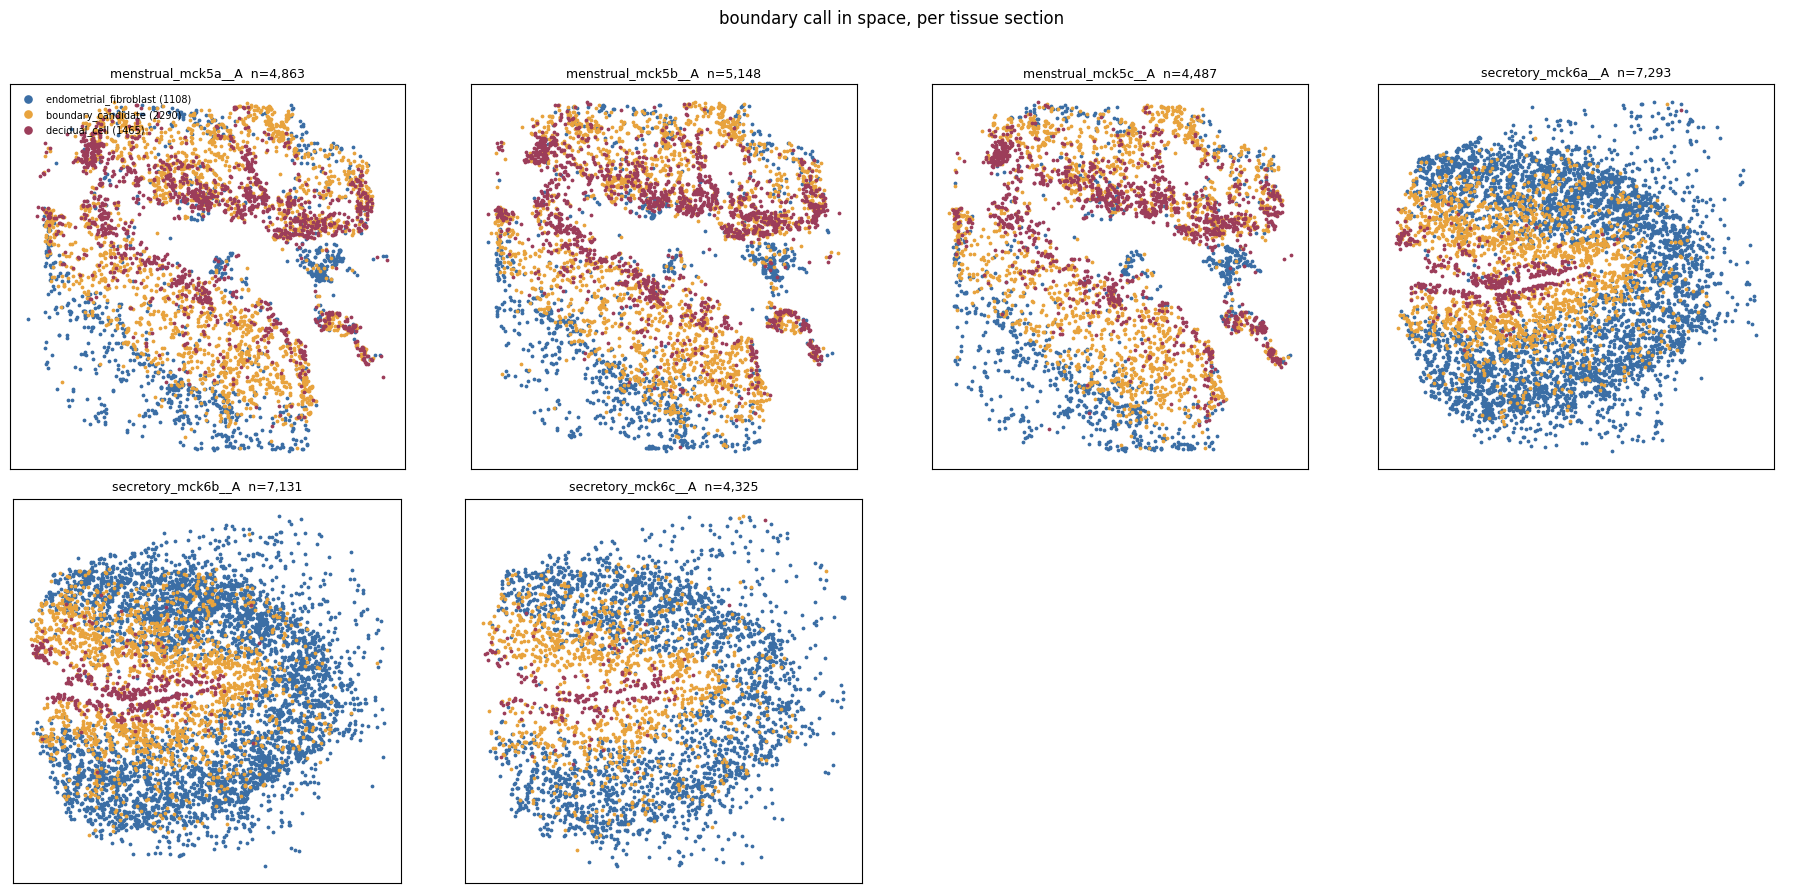

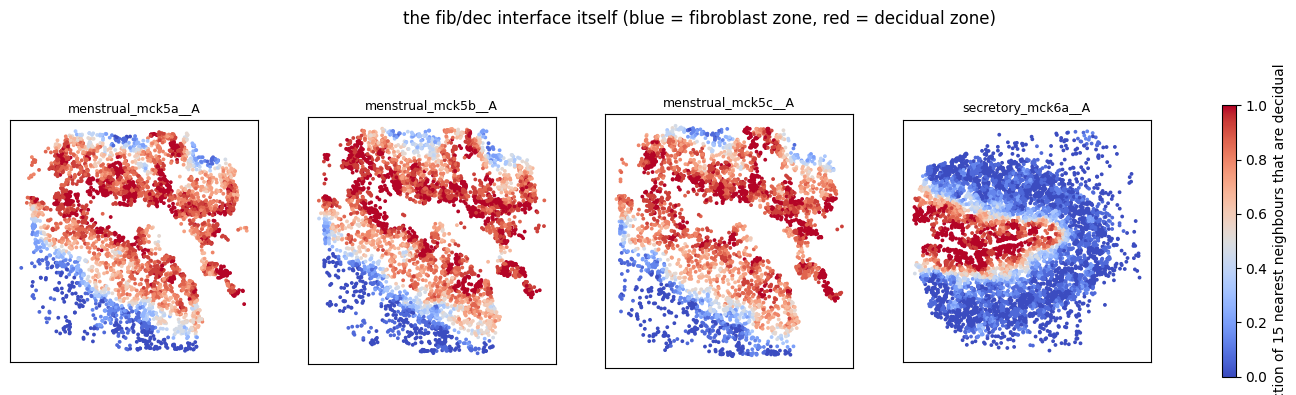

In [9]:
K = 15
SP = o[o.x_um_qc.notna() & o.y_um_qc.notna()].copy()
print("cells with coordinates:", len(SP), "| sections:", SP.tissue_section.astype(str).nunique())
fr = pd.Series(index=SP.index, dtype=float)
isdec = (SP.cell_type.astype(str) == "decidual_cell").to_numpy()
for sec, g in SP.groupby(SP.tissue_section.astype(str)):
    if len(g) < K + 1: continue
    P = g[["x_um_qc","y_um_qc"]].to_numpy(float)
    nn = NearestNeighbors(n_neighbors=min(K+1, len(g))).fit(P)
    idx = nn.kneighbors(P, return_distance=False)[:, 1:]
    fr.loc[g.index] = isdec[[g.index.get_indexer(g.index)]][0][idx].mean(axis=1) if False else \
                      (SP.cell_type.astype(str).loc[g.index].to_numpy()[idx] == "decidual_cell").mean(axis=1)
SP["frac_dec_neighbours"] = fr
SP["interface_score"] = 1 - 2 * (SP.frac_dec_neighbours - 0.5).abs()      # 1 = perfectly mixed, 0 = pure

it = SP.groupby(SP.boundary_call.astype(str)).agg(n=("interface_score","size"),
        median_interface=("interface_score","median"), mean_interface=("interface_score","mean"),
        median_frac_dec_nb=("frac_dec_neighbours","median")).round(3).reindex(CALLORDER)
print("\n=== spatial interface score by call (1 = neighbours evenly mixed) ===\n", it.to_string())
b  = SP.interface_score[SP.boundary_call.astype(str) == "boundary_candidate"].dropna()
pu = SP.interface_score[SP.boundary_call.astype(str) != "boundary_candidate"].dropna()
if len(b) and len(pu):
    u = mannwhitneyu(b, pu, alternative="greater")
    print(f"\nboundary vs pure: median {b.median():.3f} vs {pu.median():.3f} | Mann-Whitney U p={u.pvalue:.3g}")
    verify("boundary cells sit at the fib/dec interface", b.median() > pu.median(),
           f"median interface score {b.median():.3f} vs {pu.median():.3f}, p={u.pvalue:.3g}")

secs = sorted(SP.tissue_section.astype(str).unique())
nc = min(4, len(secs)); nr = int(np.ceil(len(secs)/nc))
fig, axes = plt.subplots(nr, nc, figsize=(4.6*nc, 4.4*nr), squeeze=False)
for ax, sec in zip(axes.ravel(), secs):
    g = SP[SP.tissue_section.astype(str) == sec]
    for lab in CALLORDER:
        m = g.boundary_call.astype(str) == lab
        ax.scatter(g.x_um_qc[m], g.y_um_qc[m], s=3, c=CALLPAL[lab], label=f"{lab} ({int(m.sum())})", rasterized=True)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(f"{sec}  n={len(g):,}", fontsize=9)
for ax in axes.ravel()[len(secs):]: ax.axis("off")
axes[0][0].legend(fontsize=7, markerscale=3, frameon=False, loc="upper left")
fig.suptitle("boundary call in space, per tissue section", y=1.01)
fig.tight_layout(); fig.savefig(OUT/"boundary_spatial.png", dpi=130, bbox_inches="tight")

fig, axes = plt.subplots(1, nc if len(secs) >= nc else len(secs), figsize=(4.6*min(nc,len(secs)), 4.4), squeeze=False)
for ax, sec in zip(axes.ravel(), secs[:nc]):
    g = SP[SP.tissue_section.astype(str) == sec]
    s = ax.scatter(g.x_um_qc, g.y_um_qc, s=3, c=g.frac_dec_neighbours, cmap="coolwarm", vmin=0, vmax=1, rasterized=True)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(sec, fontsize=9)
fig.colorbar(s, ax=axes.ravel().tolist(), label=f"fraction of {K} nearest neighbours that are decidual", shrink=0.8)
fig.suptitle("the fib/dec interface itself (blue = fibroblast zone, red = decidual zone)", y=1.02)
fig.savefig(OUT/"interface_map.png", dpi=130, bbox_inches="tight")

## 6b. Violins — where the call sits on each axis

                        dec_score  isodepth_consensus  dpt_pseudotime
boundary_call                                                        
endometrial_fibroblast    -0.7943              0.3147          0.3982
boundary_candidate        -0.5428              0.5307          0.4160
decidual_cell             -0.4935              0.7383          0.4473


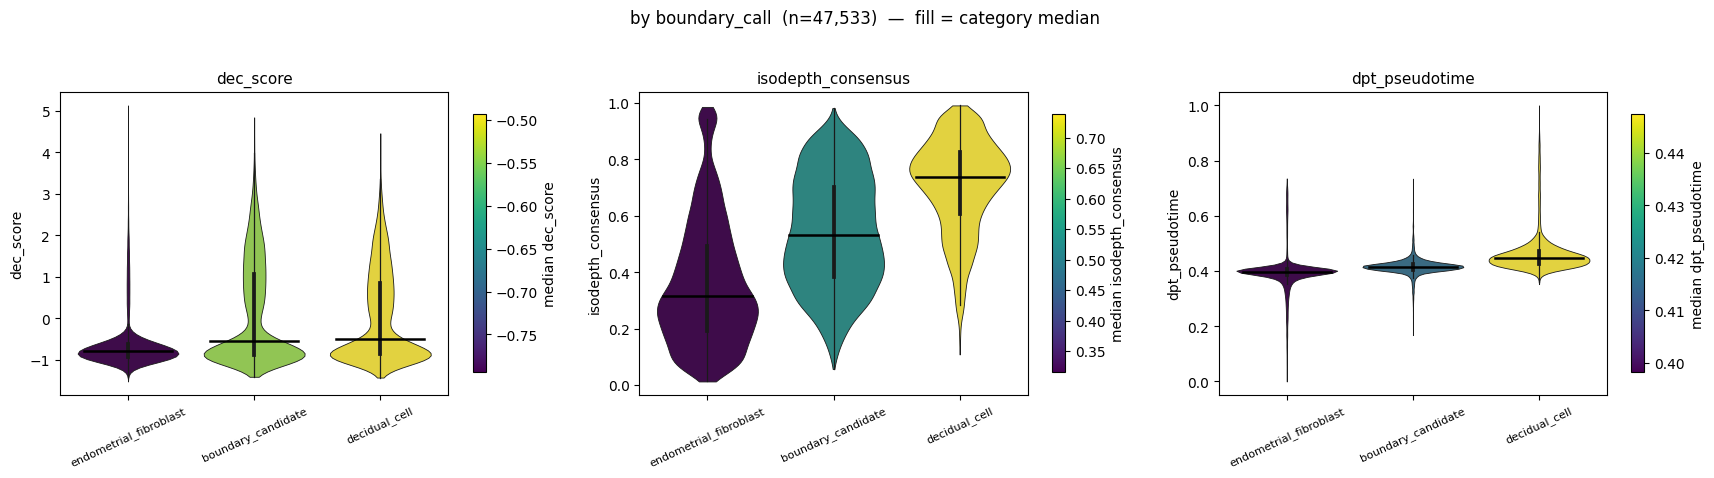

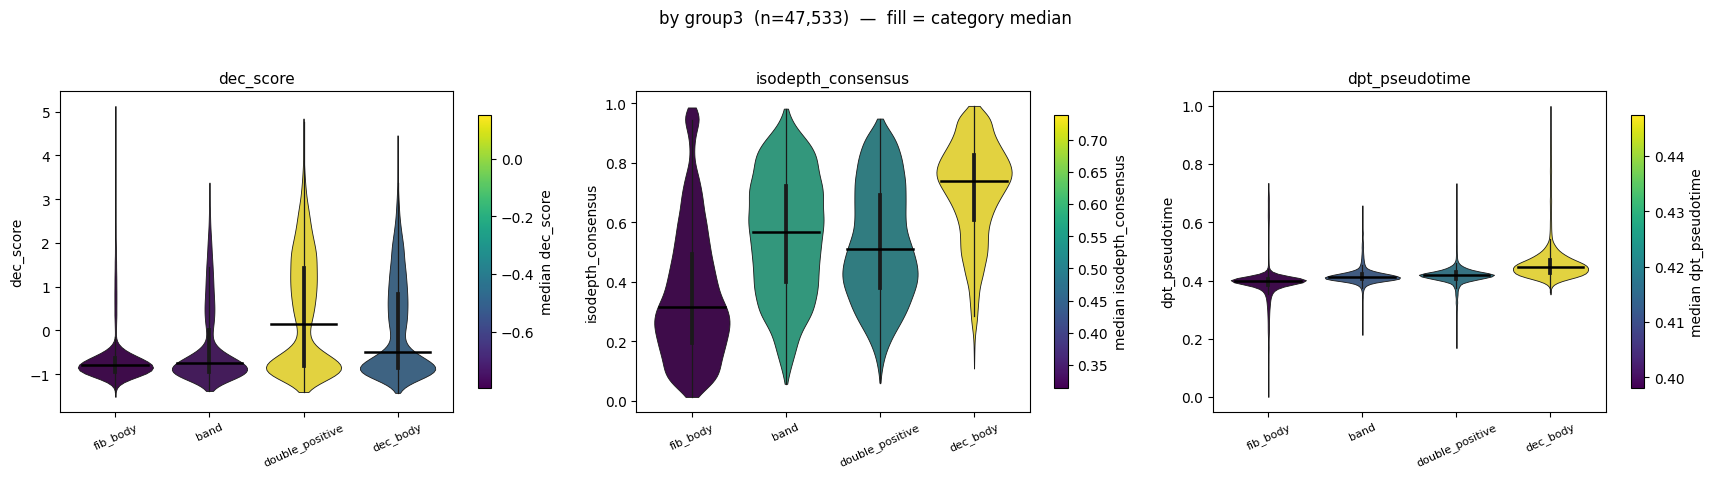

In [10]:
# ====================================================================================================
# §6b — violins (replace the whole function cell)
# ====================================================================================================
def violins(by, cols=("dec_score","isodepth_consensus","dpt_pseudotime"), order=None, cmap="viridis", figsize=None):
    """Fill colour = that category's median of the column plotted, on that column's own scale
    (so a violin's colour is the colour the tissue takes at that category's typical position).
    Black bar = median; outline = distribution."""
    d = o[o[by].notna()].copy(); d[by] = d[by].astype(str)
    present = set(d[by])
    want = order or CALLORDER
    dropped = [s for s in want if s not in present]
    order = [s for s in want if s in present]
    if dropped: print(f"  (no cells in: {dropped} -- omitted)")
    assert order, f"no categories of {by} have cells"
    cols = [c for c in cols if c in d and pd.to_numeric(d[c], errors="coerce").notna().any()]
    fig, axes = plt.subplots(1, len(cols), figsize=figsize or (5.8*len(cols), 4.6))
    axes = np.atleast_1d(axes); meds = {}
    for ax, col in zip(axes, cols):
        d[col] = pd.to_numeric(d[col], errors="coerce")
        med = d.groupby(by, observed=True)[col].median().reindex(order)
        meds[col] = med
        nrm = Normalize(vmin=float(med.min()), vmax=float(med.max()))
        # a palette entry for EVERY category in `order` -- seaborn raises on a missing key, and an
        # all-NaN median for one group must not take the whole figure down
        pal = {k: (plt.get_cmap(cmap)(nrm(med[k])) if pd.notna(med.get(k)) else (0.82, 0.82, 0.82)) for k in order}
        sns.violinplot(data=d, x=by, y=col, order=order, hue=by, hue_order=order, palette=pal,
                       legend=False, cut=0, linewidth=.6, ax=ax)
        for k, cat in enumerate(order):
            if pd.notna(med.get(cat)): ax.plot([k-.35, k+.35], [med[cat]]*2, c="k", lw=1.8, zorder=5)
        ax.set_title(col, fontsize=11); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25, labelsize=8)
        fig.colorbar(ScalarMappable(norm=nrm, cmap=cmap), ax=ax, shrink=.85, label=f"median {col}")
    fig.suptitle(f"by {by}  (n={len(d):,})  —  fill = category median", y=1.03)
    fig.tight_layout(); return fig, pd.DataFrame(meds).round(4)

f1, M1 = violins("boundary_call"); f1.savefig(OUT/"violins_boundary_call.png", dpi=130, bbox_inches="tight")
print(M1.to_string())
f2, _ = violins("group3", order=["fib_body","band","double_positive","dec_body"]); f2.savefig(OUT/"violins_group3.png", dpi=130, bbox_inches="tight")


## 7. Mouse `decidual_boundary` as the reference

Mouse has an annotated boundary subtype. Running the same interface metric on it gives the number a real boundary
population produces in this assay — the yardstick for section 6. Mouse markers are the mouse panel
(`Prl8a2/Ptgs2/Bmp2/Wnt4/Hand2`), not the human one. Skip this section if you only want the human side.

In [11]:
m = sc.read_h5ad(MOUSE)
mo = m.obs.copy()
print(m.shape, "| subtypes:", mo.cell_subtype.astype(str).nunique())
mo["is_dec"] = mo.cell_type.astype(str) == "decidual_cell"
msp = mo[mo.x_um_qc.notna() & mo.y_um_qc.notna()].copy()
fr = pd.Series(index=msp.index, dtype=float)
for sec, g in msp.groupby(msp.tissue_section.astype(str)):
    if len(g) < K + 1: continue
    P = g[["x_um_qc","y_um_qc"]].to_numpy(float)
    idx = NearestNeighbors(n_neighbors=min(K+1, len(g))).fit(P).kneighbors(P, return_distance=False)[:, 1:]
    fr.loc[g.index] = g.is_dec.to_numpy()[idx].mean(axis=1)
msp["frac_dec_neighbours"] = fr
msp["interface_score"] = 1 - 2 * (msp.frac_dec_neighbours - 0.5).abs()
MI = msp.groupby(msp.cell_subtype.astype(str)).agg(n=("interface_score","size"),
        median_interface=("interface_score","median"), median_frac_dec_nb=("frac_dec_neighbours","median")).round(3)
MORD = ["efib_outer","efib_middle","efib_middle_induced","efib_subluminal","efib_proliferative",
        "decidual_boundary","decidual_proliferative","decidual_mature","decidual_apoptotic"]
print("\n=== mouse: spatial interface score by subtype ===")
print(MI.reindex([s for s in MORD if s in MI.index]).to_string())
mb = MI.median_interface.get("decidual_boundary", np.nan)
verify("mouse decidual_boundary is the most interfacial mouse subtype",
       bool(MI.median_interface.idxmax() == "decidual_boundary"),
       f"argmax = {MI.median_interface.idxmax()} ({MI.median_interface.max():.3f}); decidual_boundary = {mb:.3f}")
try:
    hb = float(b.median())
    print(f"\nHUMAN band median interface {hb:.3f}  vs  MOUSE decidual_boundary {mb:.3f}  "
          f"(mouse pure-subtype range {MI.median_interface.min():.3f}-{MI.median_interface.max():.3f})")
except NameError:
    print("run section 6 first for the human comparison")
MI.to_csv(OUT/"mouse_interface_by_subtype.csv")

(43197, 33698) | subtypes: 9

=== mouse: spatial interface score by subtype ===
                           n  median_interface  median_frac_dec_nb
cell_subtype                                                      
efib_outer               932             0.000               0.000
efib_middle             2038             0.000               0.000
efib_middle_induced     5092             0.267               0.133
efib_subluminal         1732             0.000               0.000
efib_proliferative       367             0.000               0.000
decidual_boundary       2293             0.133               0.867
decidual_proliferative  8379             0.000               1.000
decidual_mature         2290             0.000               1.000
decidual_apoptotic       524             0.000               1.000
FAIL  mouse decidual_boundary is the most interfacial mouse subtype   [False]  argmax = efib_middle_induced (0.267); decidual_boundary = 0.133

HUMAN band median interface 0.267  vs  

## 8. Report

In [12]:
keep = [RES, "cell_type", "cell_subtype", "sample", "phase", "tissue_section", "celltype_ref",
        "dec_score", "fib_score", "dec_minus_fib", "stro7_margin", "isodepth_consensus", "dpt_pseudotime",
        "group3", "boundary_call", "x_um_qc", "y_um_qc"]
res = o[[c for c in keep if c in o]].copy()
res = res.join(SP[["frac_dec_neighbours","interface_score"]], how="left")
res.index.name = "cell"; res.to_csv(OUT/"human_boundary_calls.csv")

rep = dict(source=str(SRC), n_cells=int(len(o)), resolution=RES, band=BAND, band_clusters_A=band, doublepos_clusters_B=dpos,
           kept_decidual_markers=DECGENES, marker_auroc=auroc.auroc_dec_vs_fib.round(3).to_dict(),
           call_counts=o.boundary_call.value_counts().to_dict(),
           axis_medians=M1.to_dict(), checks=[dict(label=l, ok=ok, got=g, note=n) for l, ok, g, n in CHECKS])
json.dump(rep, open(OUT/"human_boundary_report.json","w"), indent=1, default=str)
bad = [l for l, ok, _, _ in CHECKS if not ok]
print("wrote", OUT/"human_boundary_calls.csv")
print(f"{len(CHECKS)} checks | {len(bad)} FAILED" + (": " + "; ".join(bad) if bad else " — all passed"))
print("\nNo object was modified. Calls are in the CSV only; promoting them to cell_subtype would go through")
print("resources/annotations/human_stromal.csv + annotation_vocabulary.yaml and a 04c->04d->04e re-run.")

wrote /n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/human_boundary/human_boundary_calls.csv
28 checks | 2 FAILED: dec_score separates the labels; mouse decidual_boundary is the most interfacial mouse subtype

No object was modified. Calls are in the CSV only; promoting them to cell_subtype would go through
resources/annotations/human_stromal.csv + annotation_vocabulary.yaml and a 04c->04d->04e re-run.
